# Candidate Generation (Combined) - Rolling Popularity and Niche Two-Tower MLP Model

This notebook develops a niche candidate generation model and combines its recommendations with the rolling popularity baseline. The overall candidate generation pipeline consists of two channels:

- **Popular Channel:** Retrieves the top 200 articles based on the number of clicks received in the previous hour.
- **Niche Channel:** Uses a neural network to identify relevant articles outside the popular channel's top 200, based on user preferences and article content.

The niche model uses a two-tower neural network consisting of two components:

- **User Tower:** Learns user preferences from their reading history using attention pooling.
- **Article Tower:** Learns article representations from text embeddings, entity embeddings, categories, and subcategories.

Both towers produce embeddings that are compared to measure how relevant each article is to a user. A learned freshness adjustment also accounts for how recently an article became available. Unlike the popular channel, the niche model does not use article click or display counts as model inputs, allowing it to identify potentially relevant articles that have received less exposure.

**Note:** Only information available before each impression timestamp is used to prevent data leakage.

**Objective:** The model aims to complement the popularity baseline by retrieving relevant articles that may be overlooked when recommendations are based primarily on recent popularity.

## Step 1: Setup and Reproducibility
Import the required libraries, define the input and output directories, and set random seeds to ensure reproducibility.

Define the model hyperparameters, training configurations, and evaluation settings. Include configurable switches (e.g loss function etc) to experiment with different training approaches and identify the best-performing configuration before finalizing the model.

Finally, load the shared functions for negative sampling, candidate generation evaluation, and result saving to ensure consistency across models.

In [1]:
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import copy
import random
import sys
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
import torch.nn.functional as F
from torch import nn

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)


# Run on the GPU when one is available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)


# Locate project directory
ENVIRONMENT = "local"  # 'local' or 'colab'

if ENVIRONMENT == "colab":
    from google.colab import drive

    drive.mount("/content/drive")
    CODE_ROOT = Path("/content/drive/MyDrive/BT4222-Group-6-")
    ROOT = Path("/content/drive/MyDrive/v3-mindsmall")
else:
    CODE_ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_all.py").is_file()
    )
    ROOT = Path(os.environ.get("NEWSREC_ROOT", CODE_ROOT)).expanduser().resolve()

CG_DIR = ROOT / "5_Models" / "5_01_Candidate_Generation"
CG_CODE_DIR = CODE_ROOT / "5_Models" / "5_01_Candidate_Generation"


# Load shared evaluation and result-writing functions
sys.path.insert(0, str(CG_CODE_DIR))
sys.path.insert(0, str(CG_CODE_DIR / "baseline_models"))

from cg_evaluation import CandidateEvaluator, wide_table
from cg_result_writer import CandidateWriter

# Load shared negative sampling function
sys.path.insert(0, str(CODE_ROOT / "src"))
from newsrec.training import iter_training_epoch

# Input and output directories
PROCESSED = ROOT / "1_Data_Preparation" / "processed"
REPRESENTATIONS = ROOT / "3_Representations" / "artifacts"
FEATURES = ROOT / "4_Feature_Engineering" / "artifacts" / "prequential-all"
POPULAR_DIR = CG_DIR / "artifacts" / "popularity_freshness_prior_hour_clicks"
OUTPUT_DIR = CG_DIR / "artifacts" / "niche_two_tower"
RESULTS = ROOT / "results"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "niche_two_tower"

# Experimental switches
TRAIN_ON = "all"  # 'all' or 'niche_only'
LOSS = "bpr"  # 'softmax' or 'bpr'
SELECT_BY = "ndcg"  # 'ndcg' or 'recall'

# Candidate generation and evaluation settings
POPULAR_TOP_N = 200
NICHE_DEPTH = 750
EVAL_M = tuple(range(50, NICHE_DEPTH + 1, 50))
NDCG_K = 300
RECALL_K = 300
SWEEP_K = (50, 100, 200, 300)

# Model hyperparameters
DIM = 64
MAX_HISTORY = 50
TEMPERATURE = 0.05
FRESH_BUCKETS = 12

# Training hyperparameters
N_SHOWN = 4
BATCH = 512
LEARNING_RATE = 1e-3
EPOCHS = 20
PATIENCE = 3

# Validation and retrieval settings
EARLY_STOP_SAMPLE = 8_000
SCORE_BATCH = 256
HOUR_NS = 3_600 * 10**9

# Validate experimental switches
for name, value, options in (
    ("TRAIN_ON", TRAIN_ON, ("all", "niche_only")),
    ("LOSS", LOSS, ("softmax", "bpr")),
    ("SELECT_BY", SELECT_BY, ("ndcg", "recall")),
):
    if value not in options:
        raise ValueError(f"{name} must be one of {options}")

# Define evaluation metrics
NDCG_NAME = f"long_tail_ndcg@{NDCG_K}"
RECALL_NAME = f"long_tail_recall@{RECALL_K}"

SELECT_METRIC = NDCG_NAME if SELECT_BY == "ndcg" else RECALL_NAME
RECALL_KS = tuple(sorted(set(SWEEP_K) | {RECALL_K}))

# Display configuration
print("Project:", ROOT)
print("Evaluator:", sys.modules["cg_evaluation"].__file__)
print(
    "Device:",
    DEVICE,
    torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "(CPU only)",
)
print(f"Settings: train_on={TRAIN_ON} | loss={LOSS} | select_by={SELECT_METRIC}")

Project: c:\Users\Yong Rui\BT4222-Group-6-
Evaluator: c:\Users\Yong Rui\BT4222-Group-6-\5_Models\5_01_Candidate_Generation\cg_evaluation.py
Device: cuda AMD Radeon RX 9070 XT
Settings: train_on=all | loss=bpr | select_by=long_tail_ndcg@300


## Step 2: Load and Prepare Article Features
Load the article features from the previous stages, including text and entity embeddings, categories, subcategories, and availability timestamps.

Validate that the article records and embeddings are correctly aligned. Convert article identifiers into row indices, encode categorical features, and prepare availability information for the model.

In [2]:
# Load article identifiers and validate row alignment
index = pl.read_parquet(
    REPRESENTATIONS / "article_index.parquet", columns=["article_row", "news_code"]
).sort("article_row")

N_ITEMS = index.height + 1
ROWS = index["article_row"].to_numpy().astype(np.int64)
CODES = index["news_code"].to_numpy().astype(np.int64)

if not np.array_equal(ROWS, np.arange(1, N_ITEMS)):
    raise ValueError("Article rows must start from 1, with row 0 reserved for padding")


# Create lookup tables between news codes and article rows
ROW_OF_CODE = np.zeros(int(CODES.max()) + 1, dtype=np.int64)
ROW_OF_CODE[CODES] = ROWS

CODE_OF_ROW = np.zeros(N_ITEMS, dtype=np.int32)
CODE_OF_ROW[ROWS] = CODES


def rows_for_codes(news_codes):
    """Convert news codes into article rows (0 for unknown articles)."""
    news_codes = np.asarray(news_codes, dtype=np.int64)
    rows = np.zeros(news_codes.size, dtype=np.int64)

    valid = (news_codes >= 0) & (news_codes < ROW_OF_CODE.size)
    rows[valid] = ROW_OF_CODE[news_codes[valid]]

    return rows


# Load text and entity embeddings
TEXT = np.nan_to_num(np.load(REPRESENTATIONS / "text64.npy").astype(np.float32))
ENTITY = np.nan_to_num(
    np.load(REPRESENTATIONS / "article_entity100.npy").astype(np.float32)
)

if TEXT.shape[0] != N_ITEMS or ENTITY.shape[0] != N_ITEMS:
    raise ValueError("Article embeddings do not align with article_index")

# Load article availability timestamps
availability = pl.read_parquet(
    REPRESENTATIONS / "article_availability.parquet",
    columns=["news_code", "available_from"],
)

AVAIL_NS = np.full(N_ITEMS, np.iinfo(np.int64).max, dtype=np.int64)

avail_rows = rows_for_codes(availability["news_code"].to_numpy())
avail_times = availability["available_from"].dt.epoch("ns").to_numpy()

valid = avail_rows > 0
AVAIL_NS[avail_rows[valid]] = avail_times[valid]


# Load article categories and subcategories
catalogue = pl.read_parquet(
    PROCESSED / "news_catalogue.parquet",
    columns=["news_code", "category", "subcategory"],
)

catalogue_rows = rows_for_codes(catalogue["news_code"].to_numpy())


def encode_labels(column):
    """Encode categorical labels as integers, reserving 0 for unknown values."""
    labels = catalogue[column].cast(pl.Utf8).fill_null("").to_list()

    unique_labels = sorted(set(labels) - {""})
    lookup = {label: i + 1 for i, label in enumerate(unique_labels)}

    encoded = np.array([lookup.get(label, 0) for label in labels], dtype=np.int64)

    codes = np.zeros(N_ITEMS, dtype=np.int64)
    valid = catalogue_rows > 0
    codes[catalogue_rows[valid]] = encoded[valid]

    return codes, len(lookup) + 1


CATEGORY, N_CATEGORY = encode_labels("category")
SUBCATEGORY, N_SUBCATEGORY = encode_labels("subcategory")

# Display article feature summary
print(
    f"Articles: {N_ITEMS - 1:,} | "
    f"Categories: {N_CATEGORY - 1} | "
    f"Subcategories: {N_SUBCATEGORY - 1}"
)

Articles: 51,282 | Categories: 17 | Subcategories: 264


## Step 3: Load Requests and Clicks
Load the existing training, validation, and test datasets from Stage 1, along with their corresponding user reading histories from Stage 4.

Prepare the reading histories for the user tower and retrieve clicked articles for model training and evaluation.

In [3]:
# Define the hourly time axis from the first training day
first_ts = (
    pl.scan_parquet(PROCESSED / "candidates_train.parquet")
    .select(pl.col("timestamp").min())
    .collect()
    .item()
)

T0_NS = int(
    np.datetime64(first_ts, "ns")
    .astype("datetime64[D]")
    .astype("datetime64[ns]")
    .astype(np.int64)
)


def load_requests(split):
    # Load impressions and user histories
    impressions = pl.read_parquet(
        PROCESSED / f"impressions_{split}.parquet",
        columns=["impression_uid", "timestamp"],
    )

    files = sorted((FEATURES / f"request_profiles_{split}").rglob("*.parquet"))
    if not files:
        raise FileNotFoundError(
            f"No Stage 4 request_profiles for {split} under {FEATURES}"
        )

    history_col = (
        "full_history_rows"
        if "full_history_rows" in pl.read_parquet_schema(files[0])
        else "history_rows"
    )

    requests = impressions.join(
        pl.read_parquet(files, columns=["impression_uid", history_col]),
        on="impression_uid",
        how="left",
    ).sort("timestamp", "impression_uid")

    # Flatten complete histories and record their positions
    history = requests[history_col].list.eval(pl.element().filter(pl.element() > 0))
    lengths = history.list.len().fill_null(0).to_numpy().astype(np.int64)
    flat = history.explode().drop_nulls().to_numpy().astype(np.int64)
    offsets = np.r_[0, np.cumsum(lengths)]

    # Keep the most recent MAX_HISTORY articles, padding shorter histories with zeros
    take = np.minimum(lengths, MAX_HISTORY)
    position = np.arange(MAX_HISTORY)[None, :]
    start = (offsets[1:] - take)[:, None]

    tail = np.where(
        position < take[:, None],
        np.r_[flat, 0][np.minimum(start + position, flat.size)],
        0,
    )

    ts = requests["timestamp"].dt.epoch("ns").to_numpy().astype(np.int64)

    return SimpleNamespace(
        name=split,
        uid=requests["impression_uid"].to_numpy().astype(np.int64),
        ts=ts,
        hour=(ts - T0_NS) // HOUR_NS,
        hist_tail=tail.astype(np.int64),
        hist_flat=flat,
        hist_off=offsets,
    )


def load_clicks(requests):
    # Retrieve clicked articles for each request
    lookup = pl.DataFrame(
        {"impression_uid": requests.uid, "req": np.arange(requests.uid.size)}
    )

    clicks = (
        pl.scan_parquet(PROCESSED / f"candidates_{requests.name}.parquet")
        .filter(pl.col("clicked") == 1)
        .select("impression_uid", "news_code")
        .unique()
        .collect()
        .join(lookup, on="impression_uid")
        .sort("req")
    )

    rows = rows_for_codes(clicks["news_code"].to_numpy())

    if (rows == 0).any():
        raise ValueError(
            f"{requests.name}: clicks on articles missing from article_index"
        )

    return clicks["req"].to_numpy().astype(np.int64), rows


# Load training, validation, and test requests
TRAIN = load_requests("train")
VAL = load_requests("validation")
TEST = load_requests("test")

# Load training and validation clicks
TRAIN_CLICK_REQ, TRAIN_CLICK_ROW = load_clicks(TRAIN)
VAL_CLICK_REQ, VAL_CLICK_ROW = load_clicks(VAL)

# Display dataset summary
for requests, n_clicks in ((TRAIN, TRAIN_CLICK_REQ.size), (VAL, VAL_CLICK_REQ.size)):
    print(f"{requests.name:>10}: {requests.uid.size:,} requests | {n_clicks:,} clicks")

     train: 95,071 requests | 141,558 clicks
validation: 31,624 requests | 47,961 clicks


C:\Users\Yong Rui\AppData\Local\Temp\ipykernel_9468\3463337251.py:31: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  flat = history.explode().drop_nulls().to_numpy().astype(np.int64)


## Step 4: Count Hourly Clicks and Displays
Calculate the number of times each article was displayed and clicked per hour using the existing training, validation, and test datasets from Stage 1.

Store these counts in hourly matrices for constructing the popularity-based candidate list. Only information from previous hours is used when ranking articles to prevent data leakage.

In [4]:
# Count article displays and clicks per hour
hourly = (
    pl.concat(
        [
            pl.scan_parquet(PROCESSED / f"candidates_{split}.parquet").select(
                "news_code",
                "clicked",
                ((pl.col("timestamp").dt.epoch("ns") - T0_NS) // HOUR_NS).alias("hour"),
            )
            for split in ("train", "validation", "test")
        ]
    )
    .group_by("news_code", "hour")
    .agg(shows=pl.len(), clicks=pl.col("clicked").cast(pl.Int64).sum())
    .collect()
)

# Create hourly display and click matrices
N_HOURS = (
    int(max(hourly["hour"].max(), TRAIN.hour.max(), VAL.hour.max(), TEST.hour.max()))
    + 1
)

EXPOSURES = np.zeros((N_HOURS, N_ITEMS), dtype=np.int32)
CLICKS = np.zeros((N_HOURS, N_ITEMS), dtype=np.int32)

# Populate the matrices with hourly counts
hourly_rows = rows_for_codes(hourly["news_code"].to_numpy())
hours = hourly["hour"].to_numpy()

EXPOSURES[hours, hourly_rows] = hourly["shows"].to_numpy()
CLICKS[hours, hourly_rows] = hourly["clicks"].to_numpy()

del hourly

# Display summary
print(
    f"Hours: {N_HOURS} | articles displayed at least once: {int((EXPOSURES.sum(0) > 0).sum()):,}"
)

Hours: 144 | articles displayed at least once: 20,288


## Step 5: Construct and Validate the Popularity-Based Candidate List
Construct the popular channel's top 200 articles for each hour, ranking articles by previous-hour clicks, followed by displays and article identifiers as tie-breakers.

Load the saved validation recommendations from the rolling popularity baseline and verify that the reconstructed popular lists contain the same articles. These lists are used to exclude popular articles from niche candidate generation.

In [5]:
# Rank available articles using previous-hour popularity
def popular_order(hour):
    eligible = np.flatnonzero(AVAIL_NS <= T0_NS + (hour + 1) * HOUR_NS)

    if hour == 0:
        clicks = shows = np.zeros(N_ITEMS, dtype=np.int32)
    else:
        clicks, shows = CLICKS[hour - 1], EXPOSURES[hour - 1]

    return eligible[
        np.lexsort((CODE_OF_ROW[eligible], -shows[eligible], -clicks[eligible]))
    ]


# Construct the top 200 popular articles for each hour
POPULAR_MASK = np.zeros((N_HOURS, N_ITEMS), dtype=bool)

for hour in range(N_HOURS):
    POPULAR_MASK[hour, popular_order(hour)[:POPULAR_TOP_N]] = True


# Locate the saved popularity baseline recommendations
popular_files = sorted(POPULAR_DIR.glob("recommendations_validation_top*.parquet"))

if not popular_files:
    raise FileNotFoundError(
        f"No saved popular list in {POPULAR_DIR}. "
        "Run CG_rolling_popularity_baseline.ipynb first."
    )

POPULAR_FILE = max(popular_files, key=lambda p: int(p.stem.rsplit("top", 1)[1]))

POPULAR_DEPTH = int(POPULAR_FILE.stem.rsplit("top", 1)[1])

if POPULAR_DEPTH < POPULAR_TOP_N + max(SWEEP_K):
    raise ValueError(
        f"Popular list only goes to rank {POPULAR_DEPTH}; "
        f"Step 12 needs {POPULAR_TOP_N + max(SWEEP_K)}"
    )


# Load the saved top 200 validation articles
shelf = (
    pl.scan_parquet(POPULAR_FILE)
    .filter(pl.col("cutoff") <= POPULAR_TOP_N)
    .select("impression_uid", "cutoff", "news_code")
    .collect()
    .join(
        pl.DataFrame({"impression_uid": VAL.uid, "req": np.arange(VAL.uid.size)}),
        on="impression_uid",
    )
    .sort("req", "cutoff")
)

if shelf.height != VAL.uid.size * POPULAR_TOP_N:
    raise ValueError("Saved popular list does not cover every validation request")

VAL_POPULAR = rows_for_codes(shelf["news_code"].to_numpy()).reshape(
    VAL.uid.size, POPULAR_TOP_N
)

del shelf


# Verify the reconstructed popular lists against the saved baseline
match = POPULAR_MASK[VAL.hour[:, None], VAL_POPULAR].all(axis=1).mean()

print(f"Saved popular list: {POPULAR_FILE.name}")
print(f"Rebuilt shelf matches the saved shelf for {match:.2%} of validation requests")

if match < 0.99:
    print("WARNING: the rebuilt training shelf may not follow the popular channel rule")

Saved popular list: recommendations_validation_top500.parquet
Rebuilt shelf matches the saved shelf for 100.00% of validation requests


## Step 6: Identify Niche Clicks
Identify niche clicks in the validation dataset by selecting clicked articles that fall outside the popular channel's top 200 recommendations.

These clicks represent additional relevant articles that the niche model aims to retrieve and are used to evaluate its performance.

In [6]:
# Identify validation clicks outside the popular top 200
on_shelf = (VAL_POPULAR[VAL_CLICK_REQ] == VAL_CLICK_ROW[:, None]).any(axis=1)

NICHE_REQ = VAL_CLICK_REQ[~on_shelf]
NICHE_ROW = VAL_CLICK_ROW[~on_shelf]
NICHE_IMPRESSIONS = np.unique(NICHE_REQ)


# Display niche click summary
print(
    f"Validation clicks: {VAL_CLICK_REQ.size:,} | "
    f"on the popular shelf: {on_shelf.mean():.1%} | "
    f"niche clicks: {NICHE_REQ.size:,} ({1 - on_shelf.mean():.1%})"
)
print(
    f"Requests with at least one niche click: "
    f"{NICHE_IMPRESSIONS.size:,} of {VAL.uid.size:,}"
)

Validation clicks: 47,961 | on the popular shelf: 79.6% | niche clicks: 9,778 (20.4%)
Requests with at least one niche click: 7,828 of 31,624


## Step 7: Define Niche Retrieval and Evaluation Functions
Define helper functions to generate, evaluate, and save niche candidate recommendations.

The retrieval function ranks articles based on model scores while excluding unavailable articles, popular candidates, and previously read articles.

Evaluate the retrieved candidates using two metrics (based on switch):
- Niche Recall@K: Measures the proportion of niche clicks retrieved within the top K recommendations.
- Niche NDCG@K: Measures ranking quality by rewarding relevant articles placed higher in the recommendation list.
Finally, prepare the shared evaluation and result-saving functions for subsequent steps.

In [7]:
AVAIL_T = torch.from_numpy(AVAIL_NS).to(DEVICE)


def top_niche(score_fn, requests, popular_rows, depth, subset=None, allow_short=False):
    # Prepare request indices and output arrays
    subset = np.arange(requests.uid.size) if subset is None else np.asarray(subset)
    out = np.zeros((subset.size, depth), dtype=np.int64)
    short = np.zeros(subset.size, dtype=bool)

    for start in range(0, subset.size, SCORE_BATCH):
        idx = subset[start : start + SCORE_BATCH]
        batch = np.arange(idx.size)

        # Score all articles for each request
        with torch.no_grad():
            scores = score_fn(idx).float().clone()

        # Exclude articles unavailable at the request time
        scores[
            AVAIL_T[None, :] > torch.from_numpy(requests.ts[idx]).to(DEVICE)[:, None]
        ] = -torch.inf

        # Exclude articles in the popular top 200
        scores[
            torch.from_numpy(np.repeat(batch, popular_rows.shape[1])).to(DEVICE),
            torch.from_numpy(popular_rows[idx].ravel()).to(DEVICE),
        ] = -torch.inf

        # Exclude previously read articles
        lengths = requests.hist_off[idx + 1] - requests.hist_off[idx]
        read = np.concatenate(
            [
                requests.hist_flat[requests.hist_off[i] : requests.hist_off[i + 1]]
                for i in idx
            ]
        )

        scores[
            torch.from_numpy(np.repeat(batch, lengths)).to(DEVICE),
            torch.from_numpy(read).to(DEVICE),
        ] = -torch.inf

        # Retrieve the highest-scoring eligible articles
        values, top = torch.topk(scores, depth, dim=1)

        if torch.isinf(values).any():
            if not allow_short:
                raise ValueError(
                    "Fewer niche articles available than the requested depth"
                )

            short[start : start + idx.size] = (
                torch.isinf(values).any(dim=1).cpu().numpy()
            )

        out[start : start + idx.size] = top.cpu().numpy()

    return (out, short) if allow_short else out


def niche_metrics(top_rows, subset=None):
    # Match validation niche clicks to their retrieved positions
    subset = np.arange(VAL.uid.size) if subset is None else np.asarray(subset)
    n, depth = top_rows.shape

    position = np.full(VAL.uid.size, -1, dtype=np.int64)
    position[subset] = np.arange(n)

    keep = position[NICHE_REQ] >= 0
    click_req = position[NICHE_REQ[keep]]
    click_row = NICHE_ROW[keep]

    # Identify retrieved niche clicks and their ranks
    match = top_rows[click_req] == click_row[:, None]
    found = match.any(axis=1)
    rank = np.where(found, match.argmax(axis=1) + 1, 0)

    # Calculate NDCG@K
    hit = found & (rank <= NDCG_K)

    dcg = np.bincount(click_req[hit], weights=1 / np.log2(rank[hit] + 1), minlength=n)

    relevant = np.bincount(click_req, minlength=n)
    ideal = np.r_[0, np.cumsum(1 / np.log2(np.arange(2, NDCG_K + 2)))][
        np.minimum(relevant, NDCG_K)
    ]

    has_click = relevant > 0

    result = {NDCG_NAME: float((dcg[has_click] / ideal[has_click]).mean())}

    # Calculate Recall@K
    for k in RECALL_KS:
        if k <= depth:
            result[f"long_tail_recall@{k}"] = float((found & (rank <= k)).mean())

    return result


def save_lists(path, requests, top_rows):
    # Save recommendations in the shared candidate-generation format
    depth = top_rows.shape[1]
    writer = CandidateWriter(path)

    try:
        writer.add(
            np.repeat(requests.uid, depth),
            np.tile(np.arange(1, depth + 1, dtype=np.int16), requests.uid.size),
            CODE_OF_ROW[top_rows].reshape(-1),
        )
    finally:
        writer.close()

    return path


# Initialize the shared candidate-generation evaluator
EVALUATOR = CandidateEvaluator(root=ROOT, split="validation")

## Step 8: Define the Two-Tower Model Architecture
Construct the niche two-tower neural network, consisting of an article tower and a user tower:
- Article Tower: Combines text embeddings, entity embeddings, categories, and subcategories to generate 64-dimensional article representations.
- User Tower: Uses attention pooling over the user's recent reading history to learn preferences and generate 64-dimensional user representations.
- Scoring: Calculates the similarity between user and article embeddings, with a learned freshness adjustment to help prioritise relevant and timely articles.

The model relies on article content and user reading history rather than popularity counts or learned user/article ID embeddings, allowing it to generate recommendations for new users and articles.

In [8]:
# Prepare article features as PyTorch tensors
TEXT_T = torch.from_numpy(TEXT).to(DEVICE)
ENTITY_T = torch.from_numpy(ENTITY).to(DEVICE)
CATEGORY_T = torch.from_numpy(CATEGORY).to(DEVICE)
SUBCATEGORY_T = torch.from_numpy(SUBCATEGORY).to(DEVICE)
ALL_ROWS = torch.arange(N_ITEMS, device=DEVICE)


class ArticleTower(nn.Module):
    def __init__(self):
        super().__init__()

        self.category = nn.Embedding(N_CATEGORY, 16, padding_idx=0)
        self.subcategory = nn.Embedding(N_SUBCATEGORY, 16, padding_idx=0)

        self.network = nn.Sequential(
            nn.Linear(TEXT.shape[1] + ENTITY.shape[1] + 32, 128),
            nn.ReLU(),
            nn.Linear(128, DIM),
        )

    def forward(self, rows):
        # Combine article features into normalized embeddings
        x = torch.cat(
            [
                TEXT_T[rows],
                ENTITY_T[rows],
                self.category(CATEGORY_T[rows]),
                self.subcategory(SUBCATEGORY_T[rows]),
            ],
            dim=-1,
        )

        return F.normalize(self.network(x), dim=-1)


class UserTower(nn.Module):
    def __init__(self):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(DIM, DIM), nn.Tanh(), nn.Linear(DIM, 1)
        )

        self.project = nn.Linear(DIM, DIM)
        self.new_user = nn.Parameter(torch.randn(DIM) * 0.01)

    def forward(self, history_vectors, mask):
        # Apply attention pooling to historical article embeddings
        logits = self.attention(history_vectors).squeeze(-1).masked_fill(~mask, -1e9)
        weights = torch.softmax(logits, dim=1) * mask
        pooled = (weights.unsqueeze(-1) * history_vectors).sum(1)

        # Use a learned representation for users without history
        pooled = torch.where(
            mask.any(1, keepdim=True), pooled, self.new_user.expand_as(pooled)
        )

        return F.normalize(pooled + self.project(pooled), dim=-1)


class NicheTwoTower(nn.Module):
    def __init__(self):
        super().__init__()

        self.article = ArticleTower()
        self.user = UserTower()

        self.freshness = nn.Embedding(FRESH_BUCKETS, 1)
        nn.init.zeros_(self.freshness.weight)

    def article_vectors(self):
        return self.article(ALL_ROWS)

    def user_vectors(self, hist, article_vectors):
        hist = torch.as_tensor(hist, device=article_vectors.device)
        return self.user(article_vectors[hist], hist > 0)

    def freshness_bonus(self, ts, rows):
        # Group articles by age and learn a freshness adjustment
        ts = torch.as_tensor(ts, device=AVAIL_T.device)
        rows = torch.as_tensor(rows, device=AVAIL_T.device)
        age_hours = (ts[:, None] - AVAIL_T[rows]).clamp(min=0).float() / HOUR_NS
        bucket = torch.log2(1 + age_hours).floor().long().clamp(0, FRESH_BUCKETS - 1)

        return self.freshness(bucket).squeeze(-1)

    def score(self, users, article_vectors, ts, rows):
        # Calculate user-article similarity and add freshness adjustment
        rows = torch.as_tensor(rows, device=article_vectors.device)
        vectors = article_vectors[rows]
        similarity = (
            users @ vectors.T
            if vectors.dim() == 2
            else (users.unsqueeze(1) * vectors).sum(-1)
        )

        return similarity / TEMPERATURE + self.freshness_bonus(ts, rows)


# Display total trainable parameters
print(f"Learned parameters: {sum(p.numel() for p in NicheTwoTower().parameters()):,}")

Learned parameters: 46,461


## Step 9: Prepare Training Examples and Negative Sampling
Prepare positive training examples using clicked articles, excluding articles already present in the user's reading history. Depending on the training configuration, clicks on popular articles may also be excluded.

For each positive example, randomly sample up to 4 shown-but-not-clicked articles from the same impression using the group's shared iter_training_epoch function. Negative samples are refreshed every epoch to expose the model to different training examples.

Train the model using either (based on switch):
- Softmax Cross-Entropy: Learns to rank the clicked article above the sampled negatives, placing greater emphasis on higher-scoring negatives.
- Bayesian Personalized Ranking (BPR): Learns through pairwise comparisons between clicked and unclicked articles.

In [9]:
# Prepare positive training examples
in_history = np.isin(
    TRAIN_CLICK_REQ * N_ITEMS + TRAIN_CLICK_ROW,
    np.repeat(np.arange(TRAIN.uid.size), np.diff(TRAIN.hist_off)) * N_ITEMS
    + TRAIN.hist_flat,
)

on_shelf_train = POPULAR_MASK[TRAIN.hour[TRAIN_CLICK_REQ], TRAIN_CLICK_ROW]
keep = ~in_history & (~on_shelf_train if TRAIN_ON == "niche_only" else True)
POS_REQ, POS_ROW = TRAIN_CLICK_REQ[keep], TRAIN_CLICK_ROW[keep]

EXAMPLE_UID = TRAIN.uid[POS_REQ]


def draw_shown(epoch):
    # Randomly sample shown-but-not-clicked articles for each epoch
    shown = pl.concat(
        [
            pl.from_pandas(
                frame.loc[frame["clicked"] == 0, ["impression_uid", "news_code"]]
            )
            for frame, _ in iter_training_epoch(FEATURES, epoch, columns=[])
        ]
    )

    # Match sampled negatives to their positive training examples
    pairs = pl.DataFrame(
        {"impression_uid": EXAMPLE_UID, "example": np.arange(EXAMPLE_UID.size)}
    ).join(
        shown.with_columns(pl.col("impression_uid").cast(pl.Int64)), on="impression_uid"
    )

    # Randomly select up to N_SHOWN negatives per example
    pairs = (
        pairs.with_columns(
            pl.Series(
                "order", np.random.default_rng([SEED, epoch]).random(pairs.height)
            )
        )
        .sort("example", "order")
        .with_columns(pl.int_range(pl.len()).over("example").alias("slot"))
        .filter(pl.col("slot") < N_SHOWN)
    )

    negatives = np.zeros((EXAMPLE_UID.size, N_SHOWN), dtype=np.int64)

    negatives[pairs["example"].to_numpy(), pairs["slot"].to_numpy()] = rows_for_codes(
        pairs["news_code"].to_numpy()
    )
    return negatives


# Initialize negative samples for the first epoch
FIRST_SHOWN = draw_shown(0)
SHOWN_NEG = FIRST_SHOWN

print(
    f"Clicks with shown negatives: {(SHOWN_NEG > 0).any(1).mean():.1%} | "
    f"shown negatives per click: {(SHOWN_NEG > 0).sum(1).mean():.2f}"
)


def sample_negatives(examples):
    # Retrieve negative samples and identify invalid negatives
    req = POS_REQ[examples]
    positive = POS_ROW[examples]
    negatives = SHOWN_NEG[examples]

    ignore = negatives == 0
    ignore |= negatives == positive[:, None]
    ignore |= (negatives[:, :, None] == TRAIN.hist_tail[req][:, None, :]).any(-1)

    return negatives, ignore


def training_loss(logits, ignore):
    # Calculate the selected ranking loss
    valid = ~torch.from_numpy(ignore).to(logits.device)

    if LOSS == "softmax":
        masked = torch.cat(
            [logits[:, :1], logits[:, 1:].masked_fill(~valid, -torch.inf)], dim=1
        )

        return F.cross_entropy(
            masked, torch.zeros(logits.shape[0], dtype=torch.long, device=logits.device)
        )

    # BPR pairwise ranking loss
    pairs = F.softplus(logits[:, 1:] - logits[:, :1])[valid]
    return pairs.mean() if pairs.numel() else logits.sum() * 0.0


# Check training examples and negative sampling
sample = RNG.choice(POS_REQ.size, size=min(BATCH, POS_REQ.size), replace=False)

sample_neg, sample_ignore = sample_negatives(sample)

print(
    f"Training clicks: {TRAIN_CLICK_REQ.size:,} | "
    f"already read: {in_history.sum():,} | "
    f"on the popular shelf: {on_shelf_train.mean():.1%}"
)

print(
    f"Training examples ({TRAIN_ON}): {POS_REQ.size:,} | "
    f"negatives per click: {sample_neg.shape[1]} | "
    f"ignored in a random batch: {sample_ignore.mean():.2%}"
)

Clicks with shown negatives: 100.0% | shown negatives per click: 3.77
Training clicks: 141,558 | already read: 1,881 | on the popular shelf: 80.4%
Training examples (all): 139,677 | negatives per click: 4 | ignored in a random batch: 7.18%


## Step 10: Train the Model with Early Stopping
Train the niche two-tower model using the selected loss function, with negative samples refreshed at each epoch.

After each epoch, evaluate the model using niche Recall@300 or NDCG@300 (depends on switch) on a fixed sample of validation requests. Apply early stopping to prevent overfitting by stopping training when the selected validation metric fails to improve for a specified number of epochs.

Finally, restore the best-performing model and save its weights, training history, and evaluation plots.

epoch 01 | bpr loss 0.5757 | long_tail_ndcg@300 0.0080 | long_tail_recall@300 0.0398 | 13s | BEST
epoch 02 | bpr loss 0.5437 | long_tail_ndcg@300 0.0117 | long_tail_recall@300 0.0587 | 47s | BEST
epoch 03 | bpr loss 0.5327 | long_tail_ndcg@300 0.0147 | long_tail_recall@300 0.0707 | 46s | BEST
epoch 04 | bpr loss 0.5275 | long_tail_ndcg@300 0.0201 | long_tail_recall@300 0.0890 | 47s | BEST
epoch 05 | bpr loss 0.5231 | long_tail_ndcg@300 0.0193 | long_tail_recall@300 0.0926 | 47s | patience 1/3
epoch 06 | bpr loss 0.5181 | long_tail_ndcg@300 0.0191 | long_tail_recall@300 0.0870 | 46s | patience 2/3
epoch 07 | bpr loss 0.5152 | long_tail_ndcg@300 0.0220 | long_tail_recall@300 0.0990 | 46s | BEST
epoch 08 | bpr loss 0.5124 | long_tail_ndcg@300 0.0235 | long_tail_recall@300 0.1031 | 46s | BEST
epoch 09 | bpr loss 0.5091 | long_tail_ndcg@300 0.0223 | long_tail_recall@300 0.1016 | 47s | patience 1/3
epoch 10 | bpr loss 0.5076 | long_tail_ndcg@300 0.0255 | long_tail_recall@300 0.1085 | 47s | B

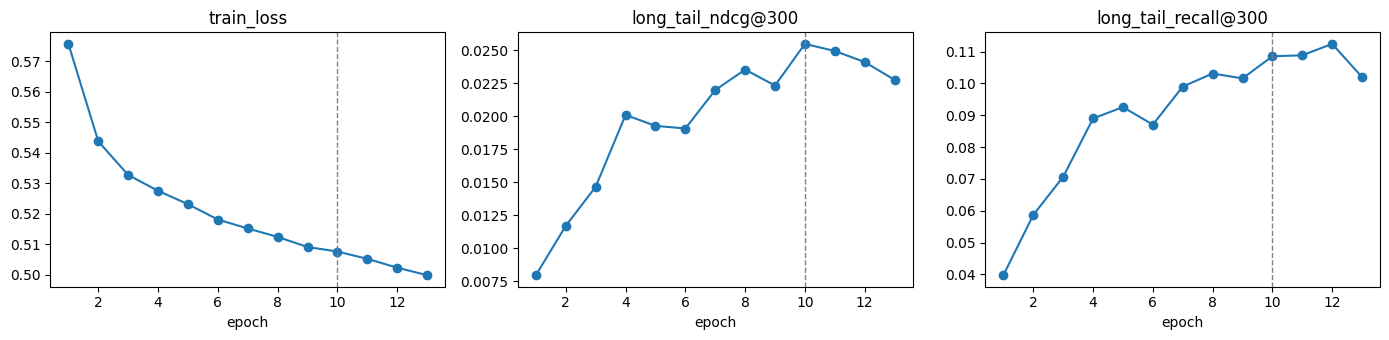

In [10]:
# Select validation requests for early stopping
early_stop_requests = np.sort(
    RNG.choice(
        NICHE_IMPRESSIONS,
        size=min(EARLY_STOP_SAMPLE, NICHE_IMPRESSIONS.size),
        replace=False,
    )
)
CHECK_DEPTH = max(NDCG_K, RECALL_K)


def model_scorer(net, article_vectors, requests):
    # Score all articles for a batch of requests
    def score_fn(idx):
        users = net.user_vectors(requests.hist_tail[idx], article_vectors)
        return net.score(users, article_vectors, requests.ts[idx], ALL_ROWS)

    return score_fn


# Initialize model and optimizer
model = NicheTwoTower().to(DEVICE)
optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = []
best_score = -1.0
best_state = None
no_improvement = 0


for epoch in range(1, EPOCHS + 1):
    started = time.time()

    # Refresh negative samples for each epoch
    SHOWN_NEG = FIRST_SHOWN if epoch == 1 else draw_shown(epoch - 1)

    # Train model
    model.train()
    losses = []
    order = RNG.permutation(POS_REQ.size)

    for start in range(0, order.size, BATCH):
        batch = order[start : start + BATCH]

        req = POS_REQ[batch]
        positive = POS_ROW[batch]
        negatives, ignore = sample_negatives(batch)

        article_vectors = model.article_vectors()
        users = model.user_vectors(TRAIN.hist_tail[req], article_vectors)

        candidates = torch.from_numpy(
            np.concatenate([positive[:, None], negatives], axis=1)
        ).to(DEVICE)
        loss = training_loss(
            model.score(users, article_vectors, TRAIN.ts[req], candidates), ignore
        )

        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        losses.append(loss.item())

    # Evaluate model on the fixed validation sample
    model.eval()

    with torch.no_grad():
        lists = top_niche(
            model_scorer(model, model.article_vectors(), VAL),
            VAL,
            VAL_POPULAR,
            CHECK_DEPTH,
            subset=early_stop_requests,
        )
    scores = niche_metrics(lists, subset=early_stop_requests)

    # Track the best-performing epoch
    improved = scores[SELECT_METRIC] > best_score

    if improved:
        best_score = scores[SELECT_METRIC]
        best_state = copy.deepcopy(model.state_dict())
        no_improvement = 0
    else:
        no_improvement += 1

    # Record training and validation metrics
    epoch_loss = float(np.mean(losses))

    history.append(
        {
            "epoch": epoch,
            "train_loss": epoch_loss,
            NDCG_NAME: scores[NDCG_NAME],
            RECALL_NAME: scores[RECALL_NAME],
            "seconds": round(time.time() - started, 1),
        }
    )

    print(
        f"epoch {epoch:02d} | {LOSS} loss {epoch_loss:.4f} | "
        f"{NDCG_NAME} {scores[NDCG_NAME]:.4f} | "
        f"{RECALL_NAME} {scores[RECALL_NAME]:.4f} | "
        f"{time.time() - started:.0f}s"
        f"{' | BEST' if improved else f' | patience {no_improvement}/{PATIENCE}'}"
    )

    # Stop training when validation performance stops improving
    if no_improvement >= PATIENCE:
        print(f"Early stopping after epoch {epoch}")
        break


# Restore and save the best model
model.load_state_dict(best_state)
torch.save({k: v.cpu() for k, v in best_state.items()}, OUTPUT_DIR / "model.pt")

TRAINING_HISTORY = pl.DataFrame(history)
TRAINING_HISTORY.write_csv(OUTPUT_DIR / "training_history.csv")

BEST_EPOCH = int(TRAINING_HISTORY.sort(SELECT_METRIC)["epoch"][-1])

print(f"Best epoch by {SELECT_METRIC}: {BEST_EPOCH}")


# Plot training loss and validation metrics
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

for ax, column in zip(axes, ("train_loss", NDCG_NAME, RECALL_NAME)):
    ax.plot(TRAINING_HISTORY["epoch"], TRAINING_HISTORY[column], marker="o")
    ax.axvline(BEST_EPOCH, color="grey", linestyle="--", linewidth=1)
    ax.set(title=column, xlabel="epoch")

plt.tight_layout()
plt.show()

## Step 11: Generate and Evaluate Niche Candidates

The best model builds a top-750 niche list for every validation request and saves it in the shared format. The lists are scored with the niche metrics and with the shared `cg_evaluation.py` at every 50 from 50 to 750.

Normal recall is expected to be low, because most clicks are on popular-shelf articles that the niche channel cannot return. Long-tail recall and NDCG are the main measures.

Outputs:

- `results/candidate_generation_niche_two_tower_validation.csv`: shared evaluation results
- `artifacts/niche_two_tower/recommendations_validation.parquet`: niche lists
- `artifacts/niche_two_tower/run_summary.csv`: settings and scores of every run

In [11]:
# Niche lists for every validation request
with torch.no_grad():
    NICHE_TOP = top_niche(
        model_scorer(model, model.article_vectors(), VAL), VAL, VAL_POPULAR, NICHE_DEPTH
    )
NICHE_FILE = save_lists(
    OUTPUT_DIR / "recommendations_validation.parquet", VAL, NICHE_TOP
)
NICHE_METRICS = niche_metrics(NICHE_TOP)
print({k: round(v, 4) for k, v in NICHE_METRICS.items()})

# Record this run's settings and scores (one row per setting combination)
summary_path = OUTPUT_DIR / "run_summary.csv"
run = pl.DataFrame(
    [
        {
            "train_on": TRAIN_ON,
            "loss": LOSS,
            "select_by": SELECT_BY,
            "best_epoch": BEST_EPOCH,
            **NICHE_METRICS,
        }
    ]
)
settings = ["train_on", "loss", "select_by"]
if summary_path.exists():
    previous = pl.read_csv(summary_path).join(
        run.select(settings), on=settings, how="anti"
    )
    run = pl.concat([previous, run], how="diagonal_relaxed")
run.sort(NDCG_NAME, descending=True).write_csv(summary_path)

# Shared evaluation (also updates the group's comparison CSV)
EVALUATION = EVALUATOR.evaluate_to_csv(
    NICHE_FILE, model_name=MODEL_NAME, m_values=EVAL_M, output_dir=RESULTS
)
wide_table(EVALUATION)

{'long_tail_ndcg@300': 0.0255, 'long_tail_recall@50': 0.043, 'long_tail_recall@100': 0.0603, 'long_tail_recall@200': 0.0881, 'long_tail_recall@300': 0.1085}


model,split,m,catalogue_coverage,cold_article_recall,hit_rate,long_tail_recall,novelty_bits,personalisation,recall_impression_mean,recall_pooled
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""niche_two_tower""","""validation""",50,0.373007,0.134503,0.012838,0.042954,15.689369,0.966913,0.008165,0.008757
"""niche_two_tower""","""validation""",100,0.513,0.172515,0.017898,0.06034,15.697061,0.961907,0.011314,0.012302
"""niche_two_tower""","""validation""",150,0.601729,0.190058,0.022515,0.075885,15.700603,0.957745,0.014451,0.015471
"""niche_two_tower""","""validation""",200,0.663448,0.210526,0.026025,0.088055,15.702848,0.954363,0.016539,0.017952
"""niche_two_tower""","""validation""",250,0.710779,0.233918,0.029092,0.098793,15.704389,0.951157,0.018468,0.020141
…,…,…,…,…,…,…,…,…,…,…
"""niche_two_tower""","""validation""",550,0.859817,0.312865,0.044144,0.152281,15.709015,0.936665,0.028379,0.031046
"""niche_two_tower""","""validation""",600,0.872544,0.315789,0.046009,0.158826,15.709483,0.934687,0.02947,0.03238
"""niche_two_tower""","""validation""",650,0.884261,0.321637,0.048096,0.166496,15.709895,0.932777,0.030948,0.033944


## Step 12: Determine the Optimal Number of Niche Candidates Using the Elbow Method
Evaluate niche Recall@K at different candidate list sizes, from 10 to 750, to examine how retrieval performance changes as more niche articles are included.

Apply the elbow method to identify the point where increasing the number of niche candidates begins to provide diminishing improvements in recall. This helps select a suitable candidate list size that balances retrieval performance and computational efficiency.

Finally, visualize the recall curve and marginal improvements, and save the results for analysis.

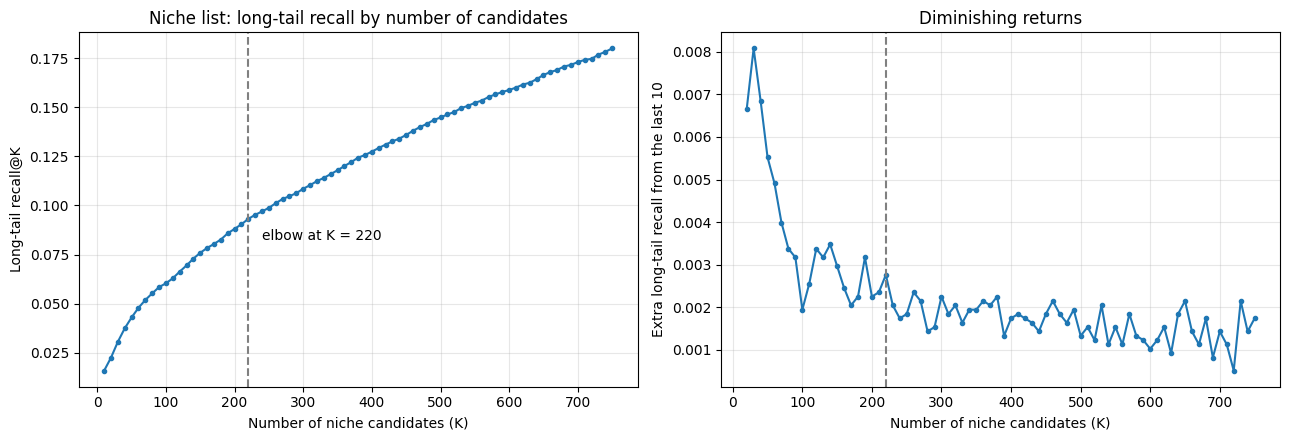

Elbow at K = 220: long-tail recall 0.093 (vs 0.180 at K = 750)


In [12]:
# Calculate niche recall at different candidate list sizes
match = NICHE_TOP[NICHE_REQ] == NICHE_ROW[:, None]
rank = np.where(match.any(axis=1), match.argmax(axis=1) + 1, 0)

CURVE_K = np.arange(10, NICHE_DEPTH + 1, 10)

curve = np.array([((rank > 0) & (rank <= k)).mean() for k in CURVE_K])

gain = np.r_[curve[0], np.diff(curve)]


# Identify the elbow point using the maximum-distance method
x = (CURVE_K - CURVE_K[0]) / (CURVE_K[-1] - CURVE_K[0])
y = (curve - curve[0]) / max(curve[-1] - curve[0], 1e-12)

ELBOW_K = int(CURVE_K[np.argmax(y - x)])


# Save recall curve and marginal improvements
pl.DataFrame(
    {"k": CURVE_K, "long_tail_recall": curve, "gain_per_10_slots": gain}
).write_csv(OUTPUT_DIR / "long_tail_recall_curve.csv")


# Visualize recall and diminishing returns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(CURVE_K, curve, marker="o", markersize=3)
ax1.annotate(
    f"elbow at K = {ELBOW_K}",
    (ELBOW_K, curve[CURVE_K == ELBOW_K][0]),
    textcoords="offset points",
    xytext=(10, -15),
)

ax1.set(
    xlabel="Number of niche candidates (K)",
    ylabel="Long-tail recall@K",
    title="Niche list: long-tail recall by number of candidates",
)

ax2.plot(CURVE_K[1:], gain[1:], marker="o", markersize=3)
ax2.set(
    xlabel="Number of niche candidates (K)",
    ylabel="Extra long-tail recall from the last 10",
    title="Diminishing returns",
)

for ax in (ax1, ax2):
    ax.axvline(ELBOW_K, linestyle="--", color="grey")
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "long_tail_recall_curve.png", dpi=150, bbox_inches="tight")
plt.show()


# Display the selected elbow point
print(
    f"Elbow at K = {ELBOW_K}: "
    f"long-tail recall {curve[CURVE_K == ELBOW_K][0]:.3f} "
    f"(vs {curve[-1]:.3f} at K = {CURVE_K[-1]})"
)

## Step 13: Configure Final Candidate Generation Settings
Choose the final candidate generation settings informed by the Step 12 elbow analysis (elbow K = 220) and the validation M sweep, including the niche budget (250), dataset splits, and filtering of previously read articles.

These settings determine how the final popular and niche candidate lists are generated without affecting the model's training or early stopping.

In [13]:
# Final candidate generation settings
PIPELINE_NICHE_K = (
    250  # chosen budget informed by the Step 12 elbow (220) and validation sweep
)
TARGET_SPLITS = ("train", "validation", "test")
FILTER_HISTORY = True


# Map dataset splits to their corresponding requests
SPLIT_REQUESTS = {"train": TRAIN, "validation": VAL, "test": TEST}

# Validate selected splits
for split in TARGET_SPLITS:
    if split not in SPLIT_REQUESTS:
        raise ValueError(
            f"Unknown split {split!r}; choose from {tuple(SPLIT_REQUESTS)}"
        )


# Display final candidate generation settings
print(
    f"Elbow from Step 12: K = {ELBOW_K} | "
    f"chosen niche size: {PIPELINE_NICHE_K} | "
    f"list length: {POPULAR_TOP_N + PIPELINE_NICHE_K}"
)

print(
    f"Target splits: {TARGET_SPLITS} | filter history in popular 200: {FILTER_HISTORY}"
)

Elbow from Step 12: K = 220 | chosen niche size: 250 | list length: 450
Target splits: ('train', 'validation', 'test') | filter history in popular 200: True


## Step 14: Generate and Evaluate the Final Combined Candidate Lists
Generate the final candidate lists for the training, validation, and test datasets by combining the popularity-based and niche recommendation channels.

For each request, retrieve the top 200 popular articles, excluding unavailable and previously read articles. The niche model then selects the top K relevant articles from the remaining candidate pool.

Combine both channels into a single candidate list, remove requests with insufficient eligible articles, and verify that no duplicate articles are included.

Finally, save the combined recommendations for downstream reranking and evaluate the validation results using the group's shared evaluation script.

In [14]:
# Define output directory and final candidate list size
PIPELINE_DIR = CG_DIR / "artifacts" / "popular_niche_combined"
PIPELINE_DIR.mkdir(parents=True, exist_ok=True)

PIPELINE_TOTAL = POPULAR_TOP_N + PIPELINE_NICHE_K


def popular_rows_for(requests, filter_history=FILTER_HISTORY):
    # Prepare popular candidate lists for each request
    out = np.zeros((requests.uid.size, POPULAR_TOP_N), dtype=np.int64)
    short = np.zeros(requests.uid.size, dtype=bool)

    for hour in np.unique(requests.hour):
        idx = np.flatnonzero(requests.hour == hour)
        ranked = popular_order(hour)[: POPULAR_TOP_N + 2_000]

        # Exclude unavailable articles
        ok = AVAIL_NS[ranked][None, :] <= requests.ts[idx][:, None]

        # Exclude previously read articles when enabled
        if filter_history:
            lengths = requests.hist_off[idx + 1] - requests.hist_off[idx]

            if lengths.sum():
                read_rows = np.concatenate(
                    [
                        requests.hist_flat[
                            requests.hist_off[i] : requests.hist_off[i + 1]
                        ]
                        for i in idx
                    ]
                )

                read = np.isin(
                    np.arange(idx.size)[:, None] * N_ITEMS + ranked[None, :],
                    np.repeat(np.arange(idx.size), lengths) * N_ITEMS + read_rows,
                )

                ok &= ~read

        # Select the first 200 eligible popular articles
        take = ok & (np.cumsum(ok, axis=1) <= POPULAR_TOP_N)
        full = take.sum(axis=1) == POPULAR_TOP_N

        out[idx[full]] = ranked[np.nonzero(take[full])[1]].reshape(-1, POPULAR_TOP_N)
        short[idx[~full]] = True

    return out, short


# Prepare trained article embeddings
model.eval()

with torch.no_grad():
    pipeline_vectors = model.article_vectors()


# Generate combined recommendations for each dataset split
PIPELINE_FILES = {}

for requests in (SPLIT_REQUESTS[split] for split in TARGET_SPLITS):
    started = time.time()

    # Generate popular candidates
    popular, popular_short = popular_rows_for(requests)

    # Generate niche candidates outside the popular list
    niche, niche_short = top_niche(
        model_scorer(model, pipeline_vectors, requests),
        requests,
        popular,
        PIPELINE_NICHE_K,
        allow_short=True,
    )

    # Combine candidates and exclude incomplete requests
    keep = ~(popular_short | niche_short)
    rows = np.concatenate([popular[keep], niche[keep]], axis=1)

    # Verify that combined lists contain no duplicate articles
    ordered = np.sort(rows, axis=1)

    if (ordered[:, 1:] == ordered[:, :-1]).any():
        raise ValueError(f"{requests.name}: duplicate articles in the combined lists")

    # Save combined candidate lists
    PIPELINE_FILES[requests.name] = save_lists(
        PIPELINE_DIR / f"recommendations_{requests.name}_top{PIPELINE_TOTAL}.parquet",
        SimpleNamespace(uid=requests.uid[keep]),
        rows,
    )

    print(
        f"{requests.name:>10}: {keep.sum():,} requests saved, "
        f"{(~keep).sum():,} skipped "
        f"({time.time() - started:.0f}s) -> {PIPELINE_FILES[requests.name].name}"
    )

    if requests.name == "train":
        print(
            "            (train lists come from the model trained on these clicks, "
            "so train recall is optimistic)"
        )


# Evaluate the combined validation recommendations
if "validation" in PIPELINE_FILES:
    PIPELINE_EVALUATION = EVALUATOR.evaluate_to_csv(
        PIPELINE_FILES["validation"],
        model_name=f"popular_niche_{POPULAR_TOP_N}_{PIPELINE_NICHE_K}",
        m_values=(PIPELINE_TOTAL,),
        output_dir=RESULTS,
        impression_uids=pl.read_parquet(
            PIPELINE_FILES["validation"], columns=["impression_uid"]
        )["impression_uid"]
        .unique()
        .to_numpy(),
    )

    print(wide_table(PIPELINE_EVALUATION))

     train: 95,059 requests saved, 12 skipped (16s) -> recommendations_train_top450.parquet
            (train lists come from the model trained on these clicks, so train recall is optimistic)
validation: 31,624 requests saved, 0 skipped (5s) -> recommendations_validation_top450.parquet
      test: 30,270 requests saved, 0 skipped (5s) -> recommendations_test_top450.parquet
shape: (1, 11)
┌────────────┬────────────┬─────┬────────────┬───┬────────────┬────────────┬───────────┬───────────┐
│ model      ┆ split      ┆ m   ┆ catalogue_ ┆ … ┆ novelty_bi ┆ personalis ┆ recall_im ┆ recall_po │
│ ---        ┆ ---        ┆ --- ┆ coverage   ┆   ┆ ts         ┆ ation      ┆ pression_ ┆ oled      │
│ str        ┆ str        ┆ i64 ┆ ---        ┆   ┆ ---        ┆ ---        ┆ mean      ┆ ---       │
│            ┆            ┆     ┆ f64        ┆   ┆ f64        ┆ f64        ┆ ---       ┆ f64       │
│            ┆            ┆     ┆            ┆   ┆            ┆            ┆ f64       ┆           │
╞═